# F4 — Integración y comunicación de resultados

**Proyecto: precios cotizados de Airbnb en Buenos Aires.**

¿Cómo varía el precio cotizado por noche en ARS según barrio, tipo y capacidad,
considerando la fecha y la duración de la estancia? El alcance es descriptivo.

Este notebook integra el reconocimiento de F1, las reglas funcionales de F2 y las
clases y verificaciones de F3 con tres visualizaciones de F4. Los gráficos leen
los CSV finales de F3: no vuelven a limpiar datos, elegir la ventana o imputar precios.
La equivalencia F2/F3 se consulta en la evidencia ya registrada; el preprocesamiento
no se vuelve a ejecutar en esta fase.

Las salidas incluidas identifican su plataforma real. La referencia Linux utiliza
entradas F3 reconstruidas y documentadas por separado; la ejecución habitual en el
equipo del proyecto exige los CSV y huellas de su propia ejecución de F3.

**Ejecución:** seleccionar `.venv` del proyecto, reiniciar el kernel y ejecutar
todas las celdas. Guardar el notebook al terminar. Detalle: `docs/entorno/ejecucion_f4.md`.

## 1. Entorno, procedencia y condiciones de ejecución

In [1]:
from pathlib import Path
import io, json, os, platform, subprocess, sys, unittest
from datetime import datetime, timezone
from importlib.metadata import version
from copy import deepcopy
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
from IPython.display import display, Image, Markdown

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'src/f3_pipeline.py').is_file() and (p/'requirements.txt').is_file()), None)
if RAIZ is None:
    raise RuntimeError('Abrir el notebook dentro del repositorio del proyecto.')
sys.path.insert(0, str(RAIZ)) if str(RAIZ) not in sys.path else None
from src.reconocimiento import (calcular_sha256, consultar_git, huella_tabla,
                                verificar_entorno, guardar_evidencia, tabla_a_registros)
from src.f3_medicion import (resumen_por_bucle, resumen_vectorizado, comprobar_resumenes,
                             comparar_implementaciones)
from src.f4_analisis import cargar_resultados_f3, preparar_resumenes, verificar_resumenes
from src.f4_visualizacion import guardar_figuras, numero

MODO = os.environ.get('MCDI500_F4_MODO', 'proyecto')
if MODO not in {'proyecto', 'referencia_linux'}:
    raise ValueError('Modo F4 desconocido.')
EVIDENCIA_F3 = RAIZ/('docs/evidencias/f3/resultados_f3.json' if MODO == 'proyecto'
                    else 'docs/evidencias/f4/referencia_linux/entradas_f3.json')
EVIDENCIAS = RAIZ/'docs/evidencias/f4'
if MODO == 'referencia_linux':
    EVIDENCIAS = EVIDENCIAS/'referencia_linux'
TABLAS = RAIZ/'docs/datos/f4'; FIGURAS = RAIZ/'docs/figuras/f4'
for carpeta in [EVIDENCIAS,TABLAS,FIGURAS]: carpeta.mkdir(parents=True, exist_ok=True)
entorno, dependencias = verificar_entorno(RAIZ)
display(entorno); display(dependencias)
assert sys.version_info[:2] == (3,13) and sys.prefix != sys.base_prefix
assert Path(sys.prefix).resolve() == (RAIZ/'.venv').resolve(), 'Seleccionar .venv del proyecto.'
assert dependencias['cumple_declaracion'].all(), 'Instalar requirements.txt en este kernel.'
for ruta in ['data/raw/listings.csv.gz','data/processed/comprobacion_f4.csv']:
    r = subprocess.run(['git','-C',str(RAIZ),'check-ignore','-q','--',ruta],capture_output=True)
    assert r.returncode == 0, f'{ruta} debe estar excluido de Git.'
r = subprocess.run(['git','-C',str(RAIZ),'ls-files','--','data/raw/','data/processed/'],
                   capture_output=True,text=True,check=True)
assert not [p for p in r.stdout.splitlines() if Path(p).name != '.gitkeep']
contexto = {'fecha_UTC':datetime.now(timezone.utc).isoformat(), 'modo':MODO,
            'metodo_ejecucion':('IPython secuencial en proceso nuevo; sin servidor Jupyter'
                                if MODO == 'referencia_linux' else 'Notebook en el entorno local del proyecto'),
            'python':platform.python_version(),'plataforma':platform.system(),
            'kernel_en_venv_proyecto':True,
            'dependencias':{n:version(n) for n in ['ipykernel','jupyterlab','notebook','numpy','pandas','matplotlib']},
            'git':consultar_git(RAIZ),'evidencia_entradas_F3':str(EVIDENCIA_F3.relative_to(RAIZ))}
print('Contexto real de esta ejecución:', contexto)

,componente,valor
0,Python,3.13.17
1,Intérprete del kernel,c:\Users\devco\Documents\Magister\proyecto-mcd...
2,Plataforma,Windows-11-10.0.26300-SP0
3,Entorno virtual activo,True
4,Kernel en .venv del proyecto,True
5,Python de la serie 3.13,True
6,pip check correcto,True
7,Salida de pip check,No broken requirements found.


,dependencia,declaracion,version_instalada,importacion_correcta,version_fijada,cumple_declaracion,observacion
0,ipykernel,ipykernel==7.4.0,7.4.0,True,True,True,Versión fijada
1,jupyterlab,jupyterlab==4.6.6,4.6.6,True,True,True,Versión fijada
2,notebook,notebook==7.6.5,7.6.5,True,True,True,Versión fijada
3,numpy,numpy==2.5.4,2.5.4,True,True,True,Versión fijada
4,pandas,pandas==3.1.0,3.1.0,True,True,True,Versión fijada
5,matplotlib,matplotlib==3.10.8,3.10.8,True,True,True,Versión fijada


Contexto real de esta ejecución: {'fecha_UTC': '2026-11-25T23:02:10.706671+00:00', 'modo': 'proyecto', 'metodo_ejecucion': 'Notebook en el entorno local del proyecto', 'python': '3.13.17', 'plataforma': 'Windows', 'kernel_en_venv_proyecto': True, 'dependencias': {'ipykernel': '7.4.0', 'jupyterlab': '4.6.6', 'notebook': '7.6.5', 'numpy': '2.5.4', 'pandas': '3.1.0', 'matplotlib': '3.10.8'}, 'git': {'disponible': True, 'rama': 'feature/f4-comunicacion-resultados', 'commit': '401d7925fc873954ef43df6148c02e6b9e5f6b01', 'cambios_sin_confirmar': True}, 'evidencia_entradas_F3': 'docs\\evidencias\\f3\\resultados_f3.json'}


## 2. Integración de F1: integridad y cobertura de la fuente

Se consultan los artefactos previos de la fuente y su huella. Los roles automáticos se
interpretan con el diccionario de F1; los identificadores no son medidas.
El precio elegido fue `price_quote_price_per_night`, cotejado con el JSON en F2:
`price` presenta un anuncio adicional, sin cotización válida para este análisis.

In [2]:
RUTAS_PREVIAS = [RAIZ/p for p in ['docs/evidencias/reconocimiento_f1.json',
    'docs/evidencias/preprocesamiento_f2.json','docs/evidencias/f3/resultados_f3.json',
    'docs/datos/f2/faltantes.csv','docs/datos/f2/comparacion_precios.csv']]
huellas_evidencias = {p:calcular_sha256(p) for p in RUTAS_PREVIAS}
evidencia_f1 = json.loads(RUTAS_PREVIAS[0].read_text(encoding='utf-8-sig'))
evidencia_f2 = json.loads(RUTAS_PREVIAS[1].read_text(encoding='utf-8-sig'))
evidencia_f3_publicada = json.loads(RUTAS_PREVIAS[2].read_text(encoding='utf-8-sig'))
huella_original = evidencia_f1['fuente']['sha256']
assert huella_original == evidencia_f2['contexto']['sha256'] == evidencia_f3_publicada['contexto']['sha256_original']
ORIGINAL = RAIZ/'data/raw/listings.csv.gz'
if ORIGINAL.is_file():
    assert calcular_sha256(ORIGINAL) == huella_original
    huellas_evidencias[ORIGINAL] = huella_original
print('Fuente registrada en F1: 29.753 filas × 90 columnas | SHA-256:',huella_original)
print('F4 no lee el CSV original ni repite el preprocesamiento.')
faltantes = pd.read_csv(RAIZ/'docs/datos/f2/faltantes.csv')
display(faltantes[['variable','n_faltantes','porcentaje_faltantes']])

Fuente registrada en F1: 29.753 filas × 90 columnas | SHA-256: c8db6461c06c0de3efbdda6821d6d28c9aef7dff3c6fde64ac4fd3661e15b78a
F4 no lee el CSV original ni repite el preprocesamiento.


,variable,n_faltantes,porcentaje_faltantes
0,id,0,0.000000
1,host_id,0,0.000000
2,last_scraped,0,0.000000
3,neighbourhood_cleansed,0,0.000000
4,room_type,0,0.000000
5,accommodates,0,0.000000
6,price,2119,7.121971
7,price_quote_price_per_night,2120,7.125332
8,price_quote_total_price,2120,7.125332
9,price_quote_checkin_date,1390,4.671798


## 3. Integración de F2 y F3: equivalencia y contrato de los CSV finales

F2 valida ARS en el JSON, precio positivo, identificadores, categorías y fechas.
No imputa precios. Conserva faltantes complementarios con indicadores, marca valores
extremos y mantiene categorías y unidades originales junto a variables derivadas.
F3 conserva estas reglas mediante herencia, estado protegido y polimorfismo.

Se consulta la equivalencia ya comprobada en F3 y se verifican las huellas,
dimensiones y subconjuntos de sus CSV finales. No se repiten las transformaciones
de F2/F3 ni se sobrescriben sus resultados.

In [3]:
tablas_f3, evidencia_f3, controles_carga = cargar_resultados_f3(RAIZ, EVIDENCIA_F3)
assert evidencia_f3['contexto']['sha256_original'] == huella_original
huellas_previas = {n:calcular_sha256(RAIZ/'data/processed'/n)
                  for n in evidencia_f3['sha256_salidas_locales']}
assert all(c['cumple'] for c in evidencia_f3_publicada['equivalencia'])
assert evidencia_f3['parametros'] == evidencia_f3_publicada['parametros']
for rol,clave in [('base','base_elegible'),('principal','grupo_principal'),('sensibilidad','grupo_adicional')]:
    assert len(tablas_f3[rol]) == evidencia_f3_publicada['resultados'][clave]
display(controles_carga)
display(pd.DataFrame(evidencia_f3_publicada['equivalencia']))
display(pd.read_csv(RAIZ/'docs/datos/f2/comparacion_precios.csv'))
print('Ventana conservada:',evidencia_f3['parametros']['SelectorGrupoComparable'])
print('Se reutilizan las salidas de F3, sin volver a procesar el dataset.')

,control,cumple
0,sha256_F3_base,True
1,sha256_F3_principal,True
2,sha256_F3_sensibilidad,True
3,principal_conserva_valores_y_seleccion_F3,True
4,sensibilidad_conserva_valores_y_seleccion_F3,True
5,principal_contenido_en_ampliacion_mensual,True


,control,cumple
0,vista_F2_F3_exacta_en_memoria,True
1,base_F2_F3_exacta_en_memoria,True
2,base_equivalente_CSV_F2,True
3,principal_equivalente_CSV_F2,True
4,sensibilidad_equivalente_CSV_F2,True


,indicador,valor
0,anuncios_totales,29753.0
1,price_presente_original,27634.0
2,price_numerico_finito,27634.0
3,price_presente_no_interpretable,0.0
4,precio_quote_presente_original,27633.0
5,precio_quote_numerico_finito,27633.0
6,ambos_numericos_finitos,27633.0
7,solo_price_finito,1.0
8,solo_precio_quote_finito,0.0
9,coinciden_tolerancia_0_01_ARS,27633.0


Ventana conservada: {'entrada': '2026-09-27', 'mes': '2026-09', 'noches': 1, 'regla': 'Mayor cobertura; empate por fecha temprana y menor duración.'}
Se reutilizan las salidas de F3, sin volver a procesar el dataset.


## 4. Eficiencia y decisiones de arquitectura

Se vuelve a verificar la equivalencia entre bucle y agrupamiento vectorizado,
con recuentos exactos y tolerancia absoluta de `1e-7 ARS` en cuartiles, sin tolerancia
relativa. Las mediciones nuevas corresponden a esta plataforma y se almacenan en F4.
Las mediciones originales de Windows se conservan en F3; no se mezclan sus tiempos.

La versión por bucle filtra `n` filas para cada uno de `g` grupos, con costo de
selección O(n·g); el agrupamiento evita esos filtrados repetidos. Los cuartiles
siguen teniendo costo de ordenación dentro de cada grupo. La agrupación almacena
índices y estructuras auxiliares: menor tiempo no implica menor memoria.
La elección se refiere a estos resúmenes, no al pipeline completo ni a todos los volúmenes.

In [4]:
comprobar_resumenes(resumen_por_bucle(tablas_f3['base']),resumen_vectorizado(tablas_f3['base']))
mediciones, repeticiones = comparar_implementaciones(tablas_f3['base'])
mediciones.to_csv(EVIDENCIAS/'mediciones_reproduccion.csv',index=False)
repeticiones.to_csv(EVIDENCIAS/'repeticiones_medicion.csv',index=False)
display(mediciones)
display(pd.read_csv(RAIZ/'docs/evidencias/f3/mediciones.csv'))

,filas,grupos,version,tiempo_min_ms,tiempo_mediana_ms,tiempo_max_ms,pico_python_mediana_MiB,resumenes_equivalentes
0,250,30,bucle,29.608367,29.748000,30.040067,0.034182,True
1,250,30,vectorizada,1.605800,1.642933,2.091600,0.030147,True
2,2080,42,bucle,44.483467,45.183967,60.805933,0.113418,True
3,2080,42,vectorizada,1.851567,1.941733,2.048833,0.133609,True
4,27633,47,bucle,91.128267,93.610467,97.115967,1.721984,True
5,27633,47,vectorizada,6.047000,6.330067,7.639000,1.937831,True


,filas,grupos,version,tiempo_min_ms,tiempo_mediana_ms,tiempo_max_ms,pico_python_mediana_MiB,resumenes_equivalentes
0,250,30,bucle,31.491833,32.025467,32.565133,0.033397,True
1,250,30,vectorizada,1.644000,1.689300,1.769767,0.030116,True
2,2080,42,bucle,45.830333,46.041433,50.153867,0.113418,True
3,2080,42,vectorizada,1.924967,2.445733,2.594767,0.133609,True
4,27633,47,bucle,92.055133,92.487800,92.726700,1.721984,True
5,27633,47,vectorizada,6.105200,6.134300,7.367967,1.937831,True


## 5. Datos interpretables, cobertura y reglas de los gráficos

Se usan los CSV finales de F3 con precio en ARS y categorías originales; la matriz
de indicadores binarios y `precio_log1p` no reemplazan estas medidas en los gráficos.
Las categorías se traducen mediante un diccionario explícito sin cambiar registros.

1. Cajas por tipo: todos los 2.080 anuncios principales; se identifican los grupos con n < 30.
2. Barrios: mismo tipo completo, capacidad 2 y estancia principal. Se muestran todos
   los barrios con n ≥ 30, umbral fijado por cobertura, no por precio.
3. Capacidad: alojamientos completos; se comparan capacidades con n ≥ 30 en ambos
   grupos. La ampliación mensual incluye al principal: no son muestras independientes.

El umbral no garantiza precisión estadística ni representatividad. Los cuartiles
describen dispersión y no son intervalos de confianza. No se eliminan extremos.

In [5]:
huellas_tablas = {k:huella_tabla(v) for k,v in tablas_f3.items()}
resumenes = preparar_resumenes(tablas_f3, minimo_grupo=30)
controles_resumen = verificar_resumenes(tablas_f3,resumenes,minimo_grupo=30)
for nombre,tabla in resumenes.items():
    tabla.to_csv(TABLAS/f'{nombre}.csv',index=False)
display(resumenes['cobertura'])
display(resumenes['tipos'])
display(resumenes['barrios'].loc[resumenes['barrios']['incluido_en_grafico']])
display(resumenes['sensibilidad_temporal'])
rutas_figuras = guardar_figuras(tablas_f3['principal'],resumenes,FIGURAS)

,seleccion,n,denominador,porcentaje
0,base_elegible,27633,27633,100.000000
1,principal,2080,27633,7.527232
2,mensual,5039,27633,18.235443
3,completos_principal,1692,2080,81.346154
4,completos_capacidad_2,713,1692,42.139480
5,barrios_con_soporte,514,713,72.089762


,tipo_alojamiento,n,mediana_ARS,q1_ARS,q3_ARS,etiqueta,grupo_pequeno
0,Entire home/apt,1692,120800.0,98302.9475,166640.85,Alojamiento completo,False
1,Hotel room,40,253784.0,199257.0000,298822.25,Habitación de hotel,False
2,Private room,329,69000.0,47000.0000,107018.00,Habitación privada,False
3,Shared room,19,35775.0,24431.0000,42654.00,Habitación compartida,True


,barrio,n,mediana_ARS,q1_ARS,q3_ARS,incluido_en_grafico
3,Belgrano,56,133924.17,99373.0000,158117.665,True
11,Monserrat,59,98762.00,87907.5000,111603.480,True
14,Palermo,203,120777.00,101972.1450,149626.000,True
18,Recoleta,91,110075.00,95551.5000,128421.000,True
19,Retiro,40,103960.00,83249.7725,142235.150,True
22,San Nicolas,65,96061.00,84085.0000,107216.000,True


grupo,capacidad,mensual,principal,cambio_mediana_porcentaje
0,2,110113.050,109964.000,0.135544
1,3,118560.000,114706.970,3.359020
2,4,137593.320,135705.000,1.391489
3,5,174285.000,169801.920,2.640182
4,6,195229.995,192936.495,1.188733


## 6. Visualización 1: diferencias por tipo de alojamiento

**Objetivo 3.** La caja permite comparar mediana y dispersión; la escala logarítmica
mantiene visibles todos los precios positivos, incluidos valores extremos. El eje
permanece expresado en ARS: distancias iguales corresponden a razones iguales.
Los símbolos fuera de los bigotes se conservan como observaciones.

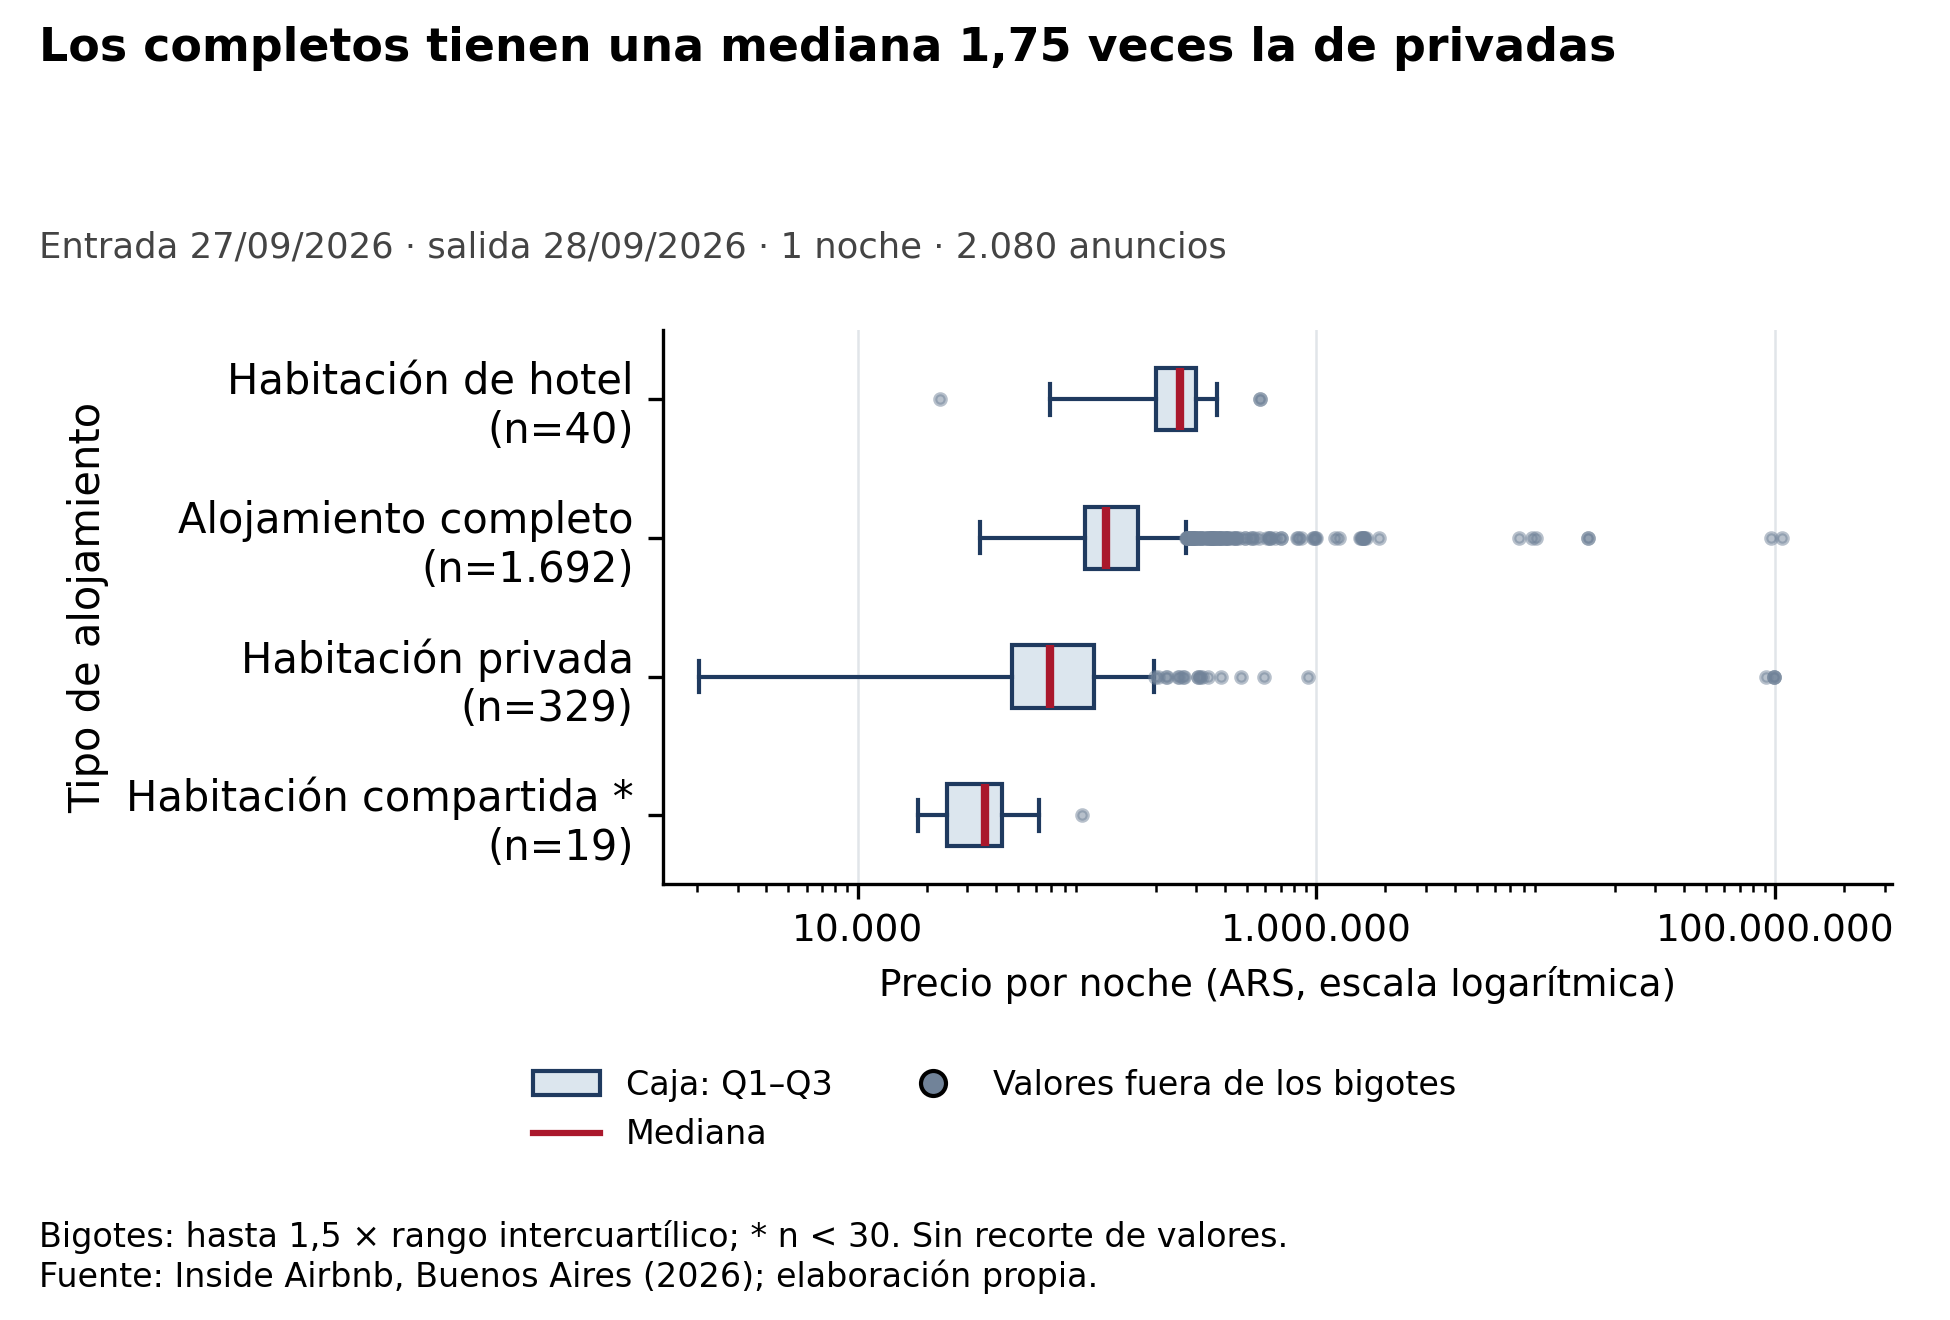

Mediana completos: 120.800,00 ARS; privadas: 69.000,00 ARS; razón: 1,75.
La diferencia no aísla barrio ni capacidad; las habitaciones compartidas tienen solo 19 anuncios.


In [6]:
display(Image(filename=str(rutas_figuras[0])))
t = resumenes['tipos'].set_index('tipo_alojamiento')
razon_tipos = t.loc['Entire home/apt','mediana_ARS']/t.loc['Private room','mediana_ARS']
print(f"Mediana completos: {numero(t.loc['Entire home/apt','mediana_ARS'],2)} ARS; "
      f"privadas: {numero(t.loc['Private room','mediana_ARS'],2)} ARS; razón: {numero(razon_tipos,2)}.")
print('La diferencia no aísla barrio ni capacidad; las habitaciones compartidas tienen solo 19 anuncios.')

## 7. Visualización 2: barrios con condiciones comparables

**Objetivos 3 y 4.** Los puntos representan medianas y los segmentos Q1–Q3.
Se mantienen tipo completo, capacidad 2 y estancia de una noche. El filtro por n
deja fuera barrios con menor cobertura, sin excluirlos de los archivos procesados.
La tabla publicada conserva también los barrios que no cumplen el umbral.

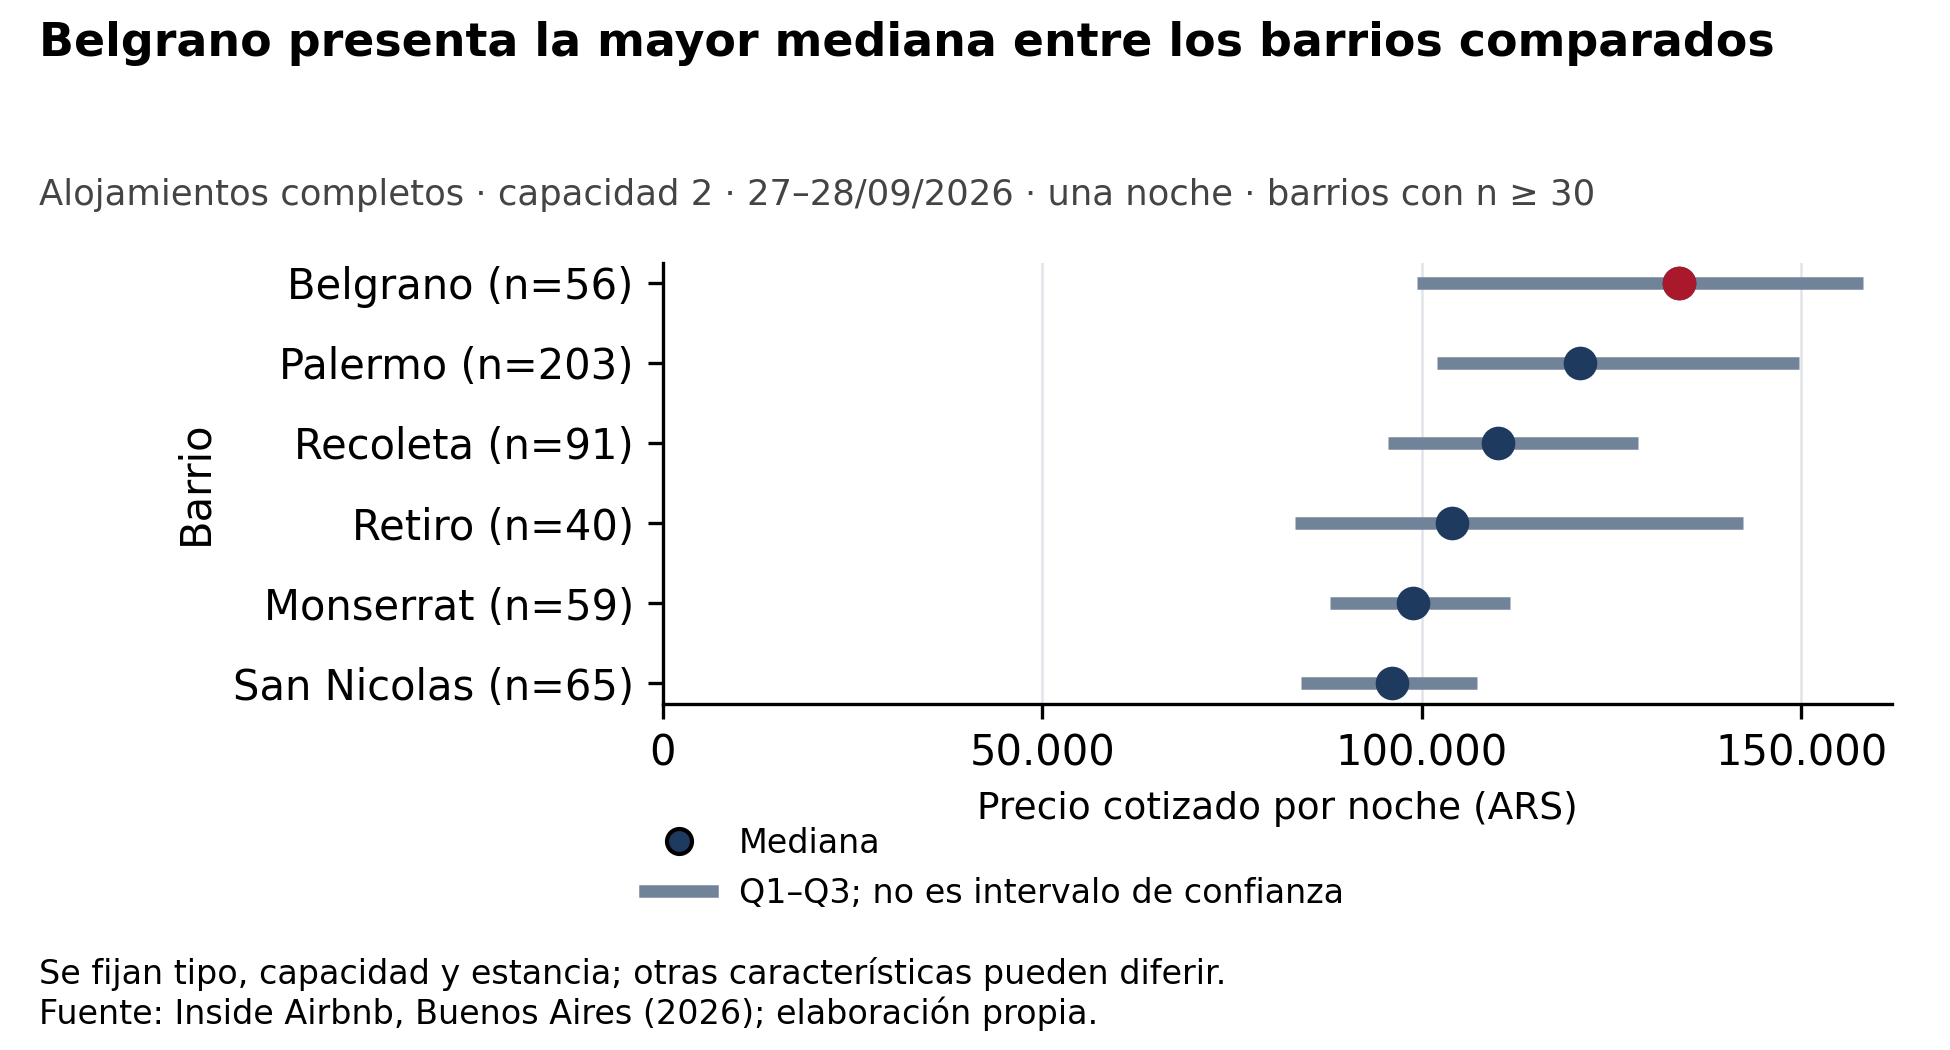

Belgrano: 133.924,17 ARS (n=56); San Nicolas: 96.061,00 ARS (n=65). Diferencia descriptiva: 39,42 % respecto de San Nicolas.
Los rangos intercuartílicos se superponen. La comparación no prueba un efecto causal del barrio.


In [7]:
display(Image(filename=str(rutas_figuras[1])))
b = resumenes['barrios'].loc[resumenes['barrios']['incluido_en_grafico']].sort_values('mediana_ARS')
menor, mayor = b.iloc[0], b.iloc[-1]
diferencia_barrios = 100*(mayor['mediana_ARS']/menor['mediana_ARS']-1)
print(f"{mayor['barrio']}: {numero(mayor['mediana_ARS'],2)} ARS (n={int(mayor['n'])}); "
      f"{menor['barrio']}: {numero(menor['mediana_ARS'],2)} ARS (n={int(menor['n'])}). "
      f"Diferencia descriptiva: {numero(diferencia_barrios,2)} % respecto de {menor['barrio']}.")
print('Los rangos intercuartílicos se superponen. La comparación no prueba un efecto causal del barrio.')

## 8. Visualización 3: capacidad y sensibilidad temporal

**Objetivos 3 y 4.** Las barras parten en cero y comparan medianas por capacidad.
Los trazos muestran dispersión Q1–Q3; las etiquetas indican el soporte de cada barra.
La ampliación conserva una noche y el tipo de alojamiento, pero puede cambiar la
composición por barrio y otras características. No representa una serie temporal,
una corrección por inflación ni una comparación entre muestras independientes.

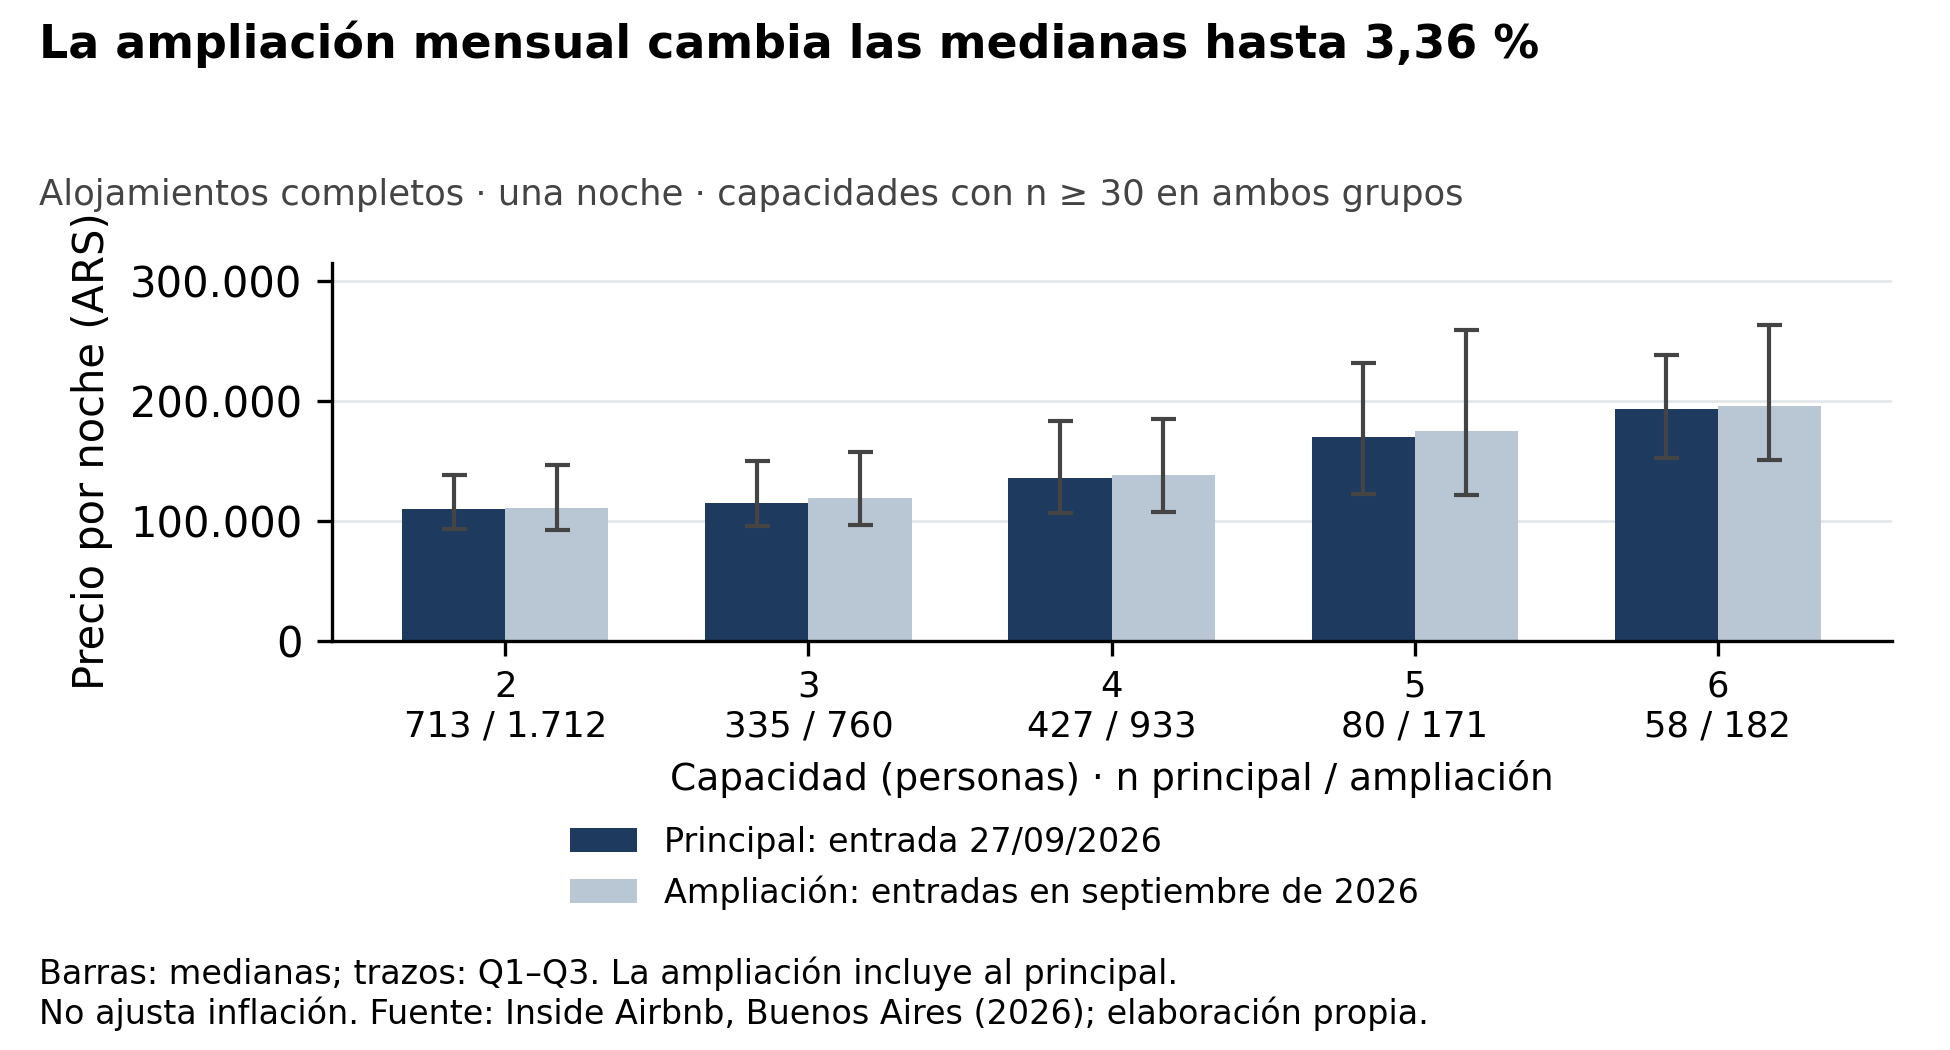

grupo,capacidad,mensual,principal,cambio_mediana_porcentaje
0,2,110113.050,109964.000,0.135544
1,3,118560.000,114706.970,3.359020
2,4,137593.320,135705.000,1.391489
3,5,174285.000,169801.920,2.640182
4,6,195229.995,192936.495,1.188733


El cambio absoluto máximo de las medianas mostradas es 3,36 %.
La fecha solicitada de estancia no acredita una misma fecha de fijación del precio.


In [8]:
display(Image(filename=str(rutas_figuras[2])))
cambios = resumenes['sensibilidad_temporal']
display(cambios)
maximo_cambio = float(cambios['cambio_mediana_porcentaje'].abs().max())
print(f'El cambio absoluto máximo de las medianas mostradas es {numero(maximo_cambio,2)} %.')
print('La fecha solicitada de estancia no acredita una misma fecha de fijación del precio.')

## 9. Resultados, discusión y conclusiones

Las diferencias observadas responden a la pregunta descriptiva de F1; no se
formularon hipótesis inferenciales ni se incorporan pruebas a posteriori para
atribuir significación a estas diferencias.

La mayor mediana entre tipos corresponde a habitaciones de hotel, con solo 40
anuncios; los completos superan a las privadas. Condicionando tipo y capacidad,
los seis barrios conservan diferencias con dispersión superpuesta. Entre capacidades
2 y 6 de alojamientos completos, las medianas aumentan y la ampliación mensual
produce cambios acotados en estos resúmenes, sin demostrar estabilidad universal.

El principal cubre solo 7,53 % de la base elegible; su composición cambia respecto
de ella. Hay múltiples anuncios por anfitrión, faltantes y valores extremos. Las
cotizaciones pueden corresponder a inmuebles distintos y no acreditan transacciones.
No se infieren demanda, ocupación, rentabilidad, causalidad ni representatividad.

Los resultados aportan referencias de oferta para comparar alojamientos similares,
acompañadas de cobertura y dispersión. Mejoras sustentadas: obtener extracciones
repetidas con fecha efectiva de cotización, revisar importes extremos en la fuente
y ampliar cruces por barrio y capacidad solo cuando tengan soporte suficiente.

In [9]:
hallazgos = pd.DataFrame([
 {'objetivo':'OE3','figura':'01_tipos.png','comparacion':'Completos / habitaciones privadas',
  'valor':float(razon_tipos),'unidad':'razón de medianas',
  'limite':'Diferencias de composición; no efecto causal del tipo.'},
 {'objetivo':'OE3–OE4','figura':'02_barrios.png','comparacion':f"{mayor['barrio']} / {menor['barrio']}",
  'valor':float(diferencia_barrios),'unidad':'porcentaje respecto del barrio de menor mediana',
  'limite':'Tipo completo, capacidad 2, seis barrios con n >= 30; cuartiles superpuestos.'},
 {'objetivo':'OE4','figura':'03_capacidades.png','comparacion':'Mayor cambio absoluto mensual / principal',
  'valor':maximo_cambio,'unidad':'porcentaje respecto de la mediana principal',
  'limite':'Capacidades 2–6, completos; grupos superpuestos; no ajusta inflación.'},
])
hallazgos.to_csv(TABLAS/'hallazgos_f4.csv',index=False)
display(hallazgos)

,objetivo,figura,comparacion,valor,unidad,limite
0,OE3,01_tipos.png,Completos / habitaciones privadas,1.750725,razón de medianas,Diferencias de composición; no efecto causal d...
1,OE3–OE4,02_barrios.png,Belgrano / San Nicolas,39.415757,porcentaje respecto del barrio de menor mediana,"Tipo completo, capacidad 2, seis barrios con n..."
2,OE4,03_capacidades.png,Mayor cambio absoluto mensual / principal,3.359020,porcentaje respecto de la mediana principal,"Capacidades 2–6, completos; grupos superpuesto..."


## 10. Validación, pruebas y reflexión técnica

Los nuevos casos verifican el contrato y las huellas de F3, rechazo de entradas
alteradas o ausentes, cuartiles con NumPy, denominadores, filtros por soporte,
precios inválidos, conservación de entradas y exportación de figuras. Se ejecuta
también la suite previa. Los datos sintéticos de las pruebas no alimentan los hallazgos.

La separación entre análisis y dibujo permite cambiar un gráfico sin modificar las
reglas F2/F3. Las funciones F4 son suficientes porque no aprenden estado; se conserva
la POO en el pipeline que sí aprende límites y ventana. La división funcional evita
recursividad artificial. El rendimiento depende de n, grupos y memoria disponible;
las mediciones no justifican extrapolar a un sistema distribuido.

In [10]:
pruebas = subprocess.run([sys.executable,'-m','unittest','discover','-s','tests'],cwd=RAIZ,
                         capture_output=True,text=True,encoding='utf-8',errors='replace')
salida_pruebas = pruebas.stdout+pruebas.stderr
(EVIDENCIAS/'pruebas_f4.txt').write_text(salida_pruebas,encoding='utf-8')
print(salida_pruebas)
assert pruebas.returncode == 0, 'Revisar pruebas_f4.txt antes de publicar resultados.'
display(controles_resumen)

..........................................
----------------------------------------------------------------------
Ran 42 tests in 2.102s

OK



,control,cumple
0,tipos_recuento_y_cuartiles_independientes,True
1,barrios_recuento_y_cuartiles_independientes,True
2,capacidades_recuento_y_cuartiles_independientes,True
3,cobertura_y_umbral_de_grupos,True


## 11. Conservación y registro de evidencia

Se verifican otra vez la fuente, los CSV de F3 y los datos en memoria. Los archivos
publicables contienen resúmenes y figuras, no identificadores ni perfiles. Las
huellas de las salidas permiten detectar sustituciones posteriores. La plataforma,
los paquetes y el commit consultado identifican el contexto de ejecución y no
afirman que estos cambios de F4 ya estén publicados en `main`.

In [11]:
for ruta,huella in huellas_evidencias.items():
    assert calcular_sha256(ruta) == huella
for nombre, huella in huellas_previas.items():
    assert calcular_sha256(RAIZ/'data/processed'/nombre) == huella
for rol, tabla in tablas_f3.items():
    assert huella_tabla(tabla) == huellas_tablas[rol]
controles = pd.concat([controles_carga,controles_resumen,pd.DataFrame([
    {'control':nombre,'cumple':True} for nombre in [
    'fuente_SHA256_consistente_entre_fases','evidencias_previas_inmutables','equivalencia_F2_F3_ya_documentada',
    'dimensiones_conservadas_de_F3','parametros_F3_documentados_inmutables','CSV_F3_inmutables',
    'tablas_F4_inmutables','bucle_vectorizado_equivalentes','suite_completa_correcta',
    'tres_figuras_exportadas']])],ignore_index=True)
assert controles['cumple'].all()
archivos_publicos = sorted(TABLAS.glob('*.csv'))+rutas_figuras
fuentes_codigo = [RAIZ/'src/f4_analisis.py',RAIZ/'src/f4_visualizacion.py',RAIZ/'tests/test_f4.py']
contenido = {
 'contexto':{**contexto,'sha256_original':huella_original},
 'resultados':{'base_elegible':len(tablas_f3['base']),'principal':len(tablas_f3['principal']),
   'mensual':len(tablas_f3['sensibilidad']),'barrios_comparados':len(b),
   'anuncios_barrios_comparados':int(b['n'].sum()),
   'maximo_cambio_mediana_porcentaje':maximo_cambio},
 'reglas':{'minimo_por_grupo':30,'barrios_tipo':'Entire home/apt','barrios_capacidad':2,
   'sin_imputacion_ni_nueva_limpieza':True,'mensual_incluye_principal':True,
   'cuartiles_no_son_intervalos_de_confianza':True},
 'controles':tabla_a_registros(controles),'hallazgos':tabla_a_registros(hallazgos),
 'sha256_entradas_F3':huellas_previas,
 'sha256_salidas_publicas':{str(p.relative_to(RAIZ)):calcular_sha256(p) for p in archivos_publicos},
 'sha256_codigo_F4':{str(p.relative_to(RAIZ)):calcular_sha256(p) for p in fuentes_codigo}}
guardar_evidencia(EVIDENCIAS/'resultados_f4.json',contenido)
controles.to_csv(EVIDENCIAS/'controles.csv',index=False)
congelado = subprocess.run([sys.executable,'-m','pip','freeze'],capture_output=True,text=True,check=True)
(EVIDENCIAS/'requirements_ejecucion.txt').write_text(congelado.stdout,encoding='utf-8')
print(f'Comprobaciones satisfactorias: {int(controles.cumple.sum())}/{len(controles)}.')
print('Tres figuras y seis tablas guardadas; fuente y resultados F3 conservados.')
print('Evidencia real:',str((EVIDENCIAS/'resultados_f4.json').relative_to(RAIZ)))
print('Guardar el notebook con Ctrl+S.')

Comprobaciones satisfactorias: 20/20.
Tres figuras y seis tablas guardadas; fuente y resultados F3 conservados.
Evidencia real: docs\evidencias\f4\resultados_f4.json
Guardar el notebook con Ctrl+S.


## 12. Referencias y comunicación final

El diseño y la separación de datos interpretables siguen las orientaciones de F4
(Universidad Andrés Bello, s. f.-a, s. f.-b). La agrupación y los resúmenes se apoyan
en pandas (The pandas development team, s. f.) y McKinney (2022). La implementación
de cajas, intervalos y escalas utiliza la documentación de Matplotlib (The Matplotlib
development team, s. f.). Las restricciones de la fuente se interpretan como
cotizaciones de oferta de Inside Airbnb (2026).

- Universidad Andrés Bello. (s. f.-a). *Guía de desarrollo: Sumativa 3, Fase 4*. https://github.com/magistercienciadatos/Material_Didactico_Semana_3/blob/cceae874db0dcb6ad6429480a8a4fd987e536c83/3_Guias_de_Apoyo/Guia_apoyo_Sumativa3_Fase4.docx
- Universidad Andrés Bello. (s. f.-b). *Apunte Fase 4*. https://github.com/magistercienciadatos/Material_Didactico_Semana_3/blob/cceae874db0dcb6ad6429480a8a4fd987e536c83/3_Guias_de_Apoyo/MCDI500_Apunte_Fase4.pdf
- The pandas development team. (s. f.). *GroupBy: Split-apply-combine*. https://pandas.pydata.org/docs/user_guide/groupby.html
- The Matplotlib development team. (s. f.). *Matplotlib 3.10.8 documentation*. https://matplotlib.org/3.10.8/
- McKinney, W. (2022). *Python for data analysis* (3.ª ed.). O’Reilly Media. https://wesmckinney.com/book/
- Inside Airbnb. (2026). *Buenos Aires: Detailed listings* [Conjunto de datos, recurso identificado como 2026-09-23; CC BY 4.0]. https://data.insideairbnb.com/argentina/ciudad-aut%C3%B3noma-de-buenos-aires/buenos-aires/2026-09-23/data/listings.csv.gz

Informe institucional: `docs/informes/MCDI500_Informe_Final_F4_Airbnb_Buenos_Aires.docx`.
Guion y apoyo visual para Canvas Studio: `docs/presentacion/guion_audiovisual_f4.md`.